In [ ]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt 
import seaborn as sns
%matplotlib inline

In [18]:
from collections import Counter
from sklearn.datasets import make_classification
X,y=make_classification(n_samples=10000,n_features=2,n_clusters_per_class=1,
                        n_redundant=0,weights=[0.99],random_state=10)



In [19]:
X

array([[ 1.87991016, -1.4850347 ],
       [ 0.37708311, -2.23858488],
       [ 1.35431163, -2.66463822],
       ...,
       [ 0.99509904, -0.54192355],
       [ 1.75859359, -1.54961188],
       [ 0.79770543, -1.99467372]])

In [20]:
Counter(y)

Counter({np.int64(0): 9846, np.int64(1): 154})

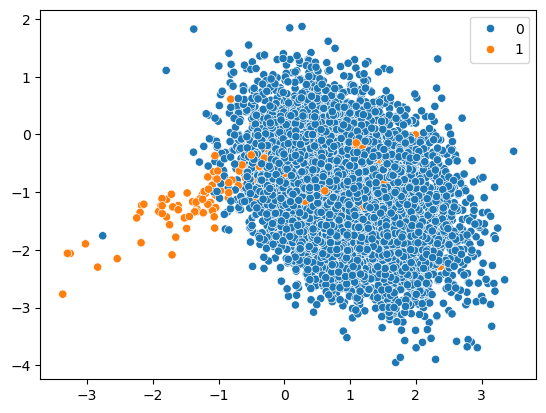

In [21]:
sns.scatterplot(x=X[:, 0], y=X[:, 1], hue=y)
plt.show()

In [22]:
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.25,random_state=10)

In [25]:
from sklearn.linear_model import LogisticRegression
logistic=LogisticRegression()
penalty=['l1','l2','elasricnet']
c_values=[100,10,1.0,0.1,0.01]
solver=['newton_sg','lbfgs','liblinear','sag','saga']
class_weight=[{0:w,1:y} for w in [1,10,50,100] for y in [1,10,50,100]]

In [26]:
class_weight

[{0: 1, 1: 1},
 {0: 1, 1: 10},
 {0: 1, 1: 50},
 {0: 1, 1: 100},
 {0: 10, 1: 1},
 {0: 10, 1: 10},
 {0: 10, 1: 50},
 {0: 10, 1: 100},
 {0: 50, 1: 1},
 {0: 50, 1: 10},
 {0: 50, 1: 50},
 {0: 50, 1: 100},
 {0: 100, 1: 1},
 {0: 100, 1: 10},
 {0: 100, 1: 50},
 {0: 100, 1: 100}]

In [27]:
params=dict(penalty=penalty,C=c_values,solver=solver,class_weight=class_weight)

In [28]:
from sklearn.model_selection import GridSearchCV
from sklearn.model_selection import StratifiedKFold
cv=StratifiedKFold()
grid=GridSearchCV(estimator=logistic,param_grid=params,scoring='accuracy',cv=cv)
grid.fit(X_train,y_train)

c:\Users\faith\anaconda3\Lib\site-packages\sklearn\linear_model\_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
c:\Users\faith\anaconda3\Lib\site-packages\sklearn\linear_model\_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
c:\Users\faith\anaconda3\Lib\site-packages\sklearn\linear_model\_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
c:\Users\faith\anaconda3\Lib\site-packages\sklearn\linear_model\_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
c:\Users\faith\anaconda3\Lib\site-packages\sklearn\linear_model\_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
c:\Users\faith\anaconda3\Lib\site-packages\sklearn\linear_model\_sag.py:348: ConvergenceWarning: The max_iter 

GridSearchCV(cv=StratifiedKFold(n_splits=5, random_state=None, shuffle=False),
             estimator=LogisticRegression(),
             param_grid={'C': [100, 10, 1.0, 0.1, 0.01],
                         'class_weight': [{0: 1, 1: 1}, {0: 1, 1: 10},
                                          {0: 1, 1: 50}, {0: 1, 1: 100},
                                          {0: 10, 1: 1}, {0: 10, 1: 10},
                                          {0: 10, 1: 50}, {0: 10, 1: 100},
                                          {0: 50, 1: 1}, {0: 50, 1: 10},
                                          {0: 50, 1: 50}, {0: 50, 1: 100},
                                          {0: 100, 1: 1}, {0: 100, 1: 10},
                                          {0: 100, 1: 50}, {0: 100, 1: 100}],
                         'penalty': ['l1', 'l2', 'elasricnet'],
                         'solver': ['newton_sg', 'lbfgs', 'liblinear', 'sag',
                                    'saga']},
             scoring='accuracy')

In [29]:
grid.best_params_

{'C': 0.01, 'class_weight': {0: 10, 1: 50}, 'penalty': 'l2', 'solver': 'lbfgs'}

In [30]:
grid.best_score_

np.float64(0.9873333333333333)

In [31]:
y_pred=grid.predict(X_test)

In [32]:
from sklearn.metrics import confusion_matrix,accuracy_score,classification_report
score=accuracy_score(y_pred,y_test)
cm=confusion_matrix(y_pred,y_test)
cr=classification_report(y_pred,y_test)
print(f"accuracy score: {score}")
print(f"Confusion matrix: {cm}")
print(f"Classification report: {cr}")

accuracy score: 0.9916
Confusion matrix: [[2469   14]
 [   7   10]]
Classification report:               precision    recall  f1-score   support

           0       1.00      0.99      1.00      2483
           1       0.42      0.59      0.49        17

    accuracy                           0.99      2500
   macro avg       0.71      0.79      0.74      2500
weighted avg       0.99      0.99      0.99      2500

